# Do finance YouTubers' stock picks beat the market?

**Google Data Analytics capstone (Track B) - reproduction notebook**

This notebook rebuilds the core results of the case study from the public dataset
`vetted_calls.csv`. The dataset contains only what my own pipeline produced (which channel
talked about which stock, when, and in which direction). It contains no transcripts and no
prices, so prices are downloaded here from Yahoo Finance.

**Expect small differences to the case-study page.** The page also uses Tiingo for companies
that have been delisted since the call; Yahoo no longer serves those, so a few dozen calls drop
out here. Yahoo also re-adjusts historical prices for dividends over time.

Structure: Ask, Prepare, Process, Analyze, Share, Act.

## 1. Ask

**Business task.** Decide whether Vetted (a side project that extracts stock calls from finance
YouTube) can present those calls as a performance signal.

1. Do buy calls beat the S&P 500 over one to twelve months, and how sure can we be?
2. Is the information in the call itself (timing, direction) or only in the kind of stocks these channels like?
3. Do channels differ from each other by more than chance would produce?

## 2. Prepare

Load the dataset and look at what is in it.

In [1]:
import warnings, os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

CANDIDATES = ["/kaggle/input/vetted-finance-youtube-stock-calls/vetted_calls.csv",
              "../data/public/vetted_calls.csv", "vetted_calls.csv"]
path = next(p for p in CANDIDATES if os.path.exists(p))
calls = pd.read_csv(path, parse_dates=["video_date"])
print(calls.shape)
calls.head()

(5461, 13)


,call_id,video_id,channel,language,video_date,ticker,company_name,direction,llm_label,llm_confidence,mention_count,in_depth,is_repeat_90d
0,1,MoZAMF2IUI4,"Let's Talk Money! with Joseph Hogue, CFA",en,2024-03-01,IBM,International Business Machines,buy,buy,0.78,5,True,False
1,2,MoZAMF2IUI4,"Let's Talk Money! with Joseph Hogue, CFA",en,2024-03-01,WBA,Walgreens Boots Alliance,buy,buy,0.72,4,True,False
2,3,MoZAMF2IUI4,"Let's Talk Money! with Joseph Hogue, CFA",en,2024-03-01,INTC,Intel,bearish,sell,0.65,3,False,False
3,4,MoZAMF2IUI4,"Let's Talk Money! with Joseph Hogue, CFA",en,2024-03-01,BABA,Alibaba Group Holdings,buy,buy,0.76,4,True,False
4,5,GdZhxxQ_a54,Everything Money,en,2024-03-02,GOOGL,Alphabet Inc.,buy,buy,0.92,12,True,False


In [2]:
print("period:", calls.video_date.min().date(), "to", calls.video_date.max().date())
print("channels:", calls.channel.nunique(), "| videos:", calls.video_id.nunique(), "| tickers:", calls.ticker.nunique())
calls.groupby(["channel", "direction"]).size().unstack(fill_value=0).sort_values("buy", ascending=False)

period: 2024-03-01 to 2026-03-28
channels: 12 | videos: 1295 | tickers: 763


direction,bearish,buy
channel,,
"Let's Talk Money! with Joseph Hogue, CFA",319,1713
Everything Money,410,727
ZipTrader,58,497
Tom Nash,61,471
Joseph Carlson,108,218
Finanzbär,16,157
New Money,104,102
Brian Feroldi,39,75
Sven Carlin,106,62


**Data quality in one paragraph.** The `direction` label is written by a small language model
(Claude Haiku). In a manual audit of 140 randomly drawn calls, 71% of the `buy` labels were a
genuine positive view of the creator, and only 40% of the `bearish` labels a genuine negative
view. Calls where the stock is named at least four times in the video (`in_depth`) were correct
in 30 of 31 audited cases. Read every result below with that noise in mind.

## 3. Process

Cleaning already happened before export (see `JOURNAL.md` in the repository): directional
labels only, single US-listed stocks, core channels, one call per channel/stock/day.
What remains to do here is attach prices.

* **Entry** = first close *after* the video date (only the date is known, not the time).
* **Horizons** = 30 / 90 / 180 / 365 calendar days after entry.
* **Excess return** = stock return minus SPY return over exactly the same dates.

In [3]:
import logging, yfinance as yf
logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # delisted tickers are reported below instead

START, END = "2024-02-01", "2026-11-14"          # fixed end date keeps the notebook reproducible
tickers = sorted(set(calls.ticker) | {"SPY", "QQQ"})
frames = []
for i in range(0, len(tickers), 100):
    chunk = tickers[i:i + 100]
    df = yf.download(chunk, start=START, end=END, auto_adjust=True, progress=False, threads=True)["Close"]
    frames.append(df if isinstance(df, pd.DataFrame) else df.to_frame(chunk[0]))
    time.sleep(1)
px = pd.concat(frames, axis=1).sort_index()
px = px.loc[px["SPY"].notna()]
px = px.dropna(axis=1, how="all")
missing = sorted(set(tickers) - set(px.columns))
print(f"{px.shape[1]} tickers with prices, {len(missing)} not served by Yahoo (mostly delisted): {missing[:15]}")

727 tickers with prices, 38 not served by Yahoo (mostly delisted): ['ABB', 'AC', 'AKER', 'AMPS', 'ARCH', 'ATKR', 'ATSG', 'BKH', 'BLOCK', 'BPMC', 'CEIX', 'DOOO', 'DVS', 'EA', 'FI']


In [4]:
HORIZONS = [30, 90, 180, 365]
cal, last = px.index, px.index[-1]

def on_or_before(s, day):
    s = s.loc[:day].dropna()
    return (s.index[-1], s.iloc[-1]) if len(s) else (pd.NaT, np.nan)

rows = []
for r in calls.itertuples():
    out = {"call_id": r.call_id}
    if r.ticker in px.columns:
        s = px[r.ticker].dropna()
        pos = cal.searchsorted(r.video_date, side="right")
        if pos < len(cal) and cal[pos] in s.index and (cal[pos] - r.video_date).days <= 5:
            d0 = cal[pos]
            for h in HORIZONS:
                end = d0 + pd.Timedelta(days=h)
                if end > last:
                    continue
                e_day, _ = on_or_before(px["SPY"], end)
                s_day, p1 = on_or_before(s, end)
                if s_day < e_day - pd.Timedelta(days=7):
                    continue                      # series stops early (delisted) - skipped here
                ret = p1 / s[d0] - 1
                out[f"ret_{h}"] = ret
                out[f"ex_{h}"] = ret - (px.at[e_day, "SPY"] / px.at[d0, "SPY"] - 1)
                out[f"exq_{h}"] = ret - (px.at[e_day, "QQQ"] / px.at[d0, "QQQ"] - 1)
    rows.append(out)
d = calls.merge(pd.DataFrame(rows), on="call_id")
d["month"] = d.video_date.dt.to_period("M").astype(str)
print("calls with a 90-day return:", d.ex_90.notna().sum(), "of", len(d))
buy, bear = d[d.direction == "buy"], d[d.direction == "bearish"]

calls with a 90-day return: 5369 of 5461


## 4. Analyze

### Uncertainty
The calls are not independent: a channel repeats the same stock many times, and all calls of
one month share one market. Standard errors are therefore clustered **two ways, by ticker and
by month** (Cameron, Gelbach & Miller). The helper below does this for a simple mean.

In [5]:
def clustered_mean(df, col):
    x = df[[col, "ticker", "month"]].dropna()
    y = x[col].to_numpy(float); e = y - y.mean(); n = len(y)
    def var(keys):
        codes = pd.factorize(keys)[0]; G = codes.max() + 1
        return (np.bincount(codes, weights=e) ** 2).sum() * G / (G - 1) / n ** 2, G
    vt, gt = var(x["ticker"]); vm, gm = var(x["month"]); vx, _ = var(x["ticker"] + "|" + x["month"])
    se = np.sqrt(max(vt + vm - vx, 1e-18)); dof = min(gt, gm) - 1
    half = stats.t.ppf(0.975, dof) * se
    return pd.Series({"n": n, "mean": y.mean() * 100, "ci_low": (y.mean() - half) * 100,
                      "ci_high": (y.mean() + half) * 100, "p": 2 * stats.t.sf(abs(y.mean() / se), dof)})

### Finding 1 - More than half of the buy calls did worse than the S&P 500

In [6]:
table = []
for h in HORIZONS:
    s = clustered_mean(buy, f"ex_{h}"); x = buy[f"ex_{h}"].dropna()
    table.append({"horizon": f"{h}d", "calls": int(s.n), "mean excess (pp)": s["mean"], "95% CI low": s.ci_low,
                  "95% CI high": s.ci_high, "median excess (pp)": x.median() * 100, "share beating SPY (%)": (x > 0).mean() * 100})
pd.DataFrame(table).set_index("horizon").round(2)

,calls,mean excess (pp),95% CI low,95% CI high,median excess (pp),share beating SPY (%)
horizon,,,,,,
30d,4046,0.28,-1.14,1.71,-0.65,47.03
90d,4046,2.24,-1.20,5.68,-1.85,45.55
180d,4046,7.65,1.25,14.04,-1.01,48.15
365d,3126,11.61,-1.86,25.09,-1.90,47.47


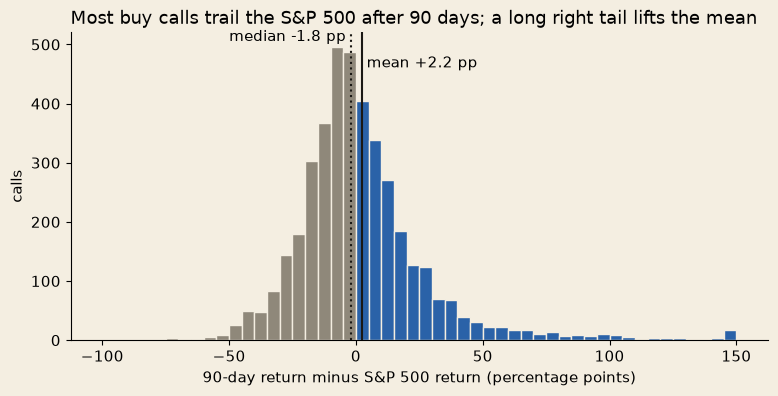

In [7]:
INK, BLUE, RUST, CREAM = "#1A1814", "#2A62A8", "#C2552D", "#F4EEE1"
plt.rcParams.update({"figure.facecolor": CREAM, "axes.facecolor": CREAM, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
x = buy.ex_90.dropna() * 100
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(-100, 155, 5)
n, edges, patches = ax.hist(x.clip(-100, 149.9), bins=bins, edgecolor=CREAM)
for p, left in zip(patches, edges[:-1]):
    p.set_facecolor(BLUE if left >= 0 else "#8f887a")
ax.axvline(x.median(), color=INK, ls=":", lw=1.5); ax.axvline(x.mean(), color=INK, lw=1.5)
ax.text(x.median() - 2, n.max() * 1.02, f"median {x.median():+.1f} pp", ha="right")
ax.text(x.mean() + 2, n.max() * 0.93, f"mean {x.mean():+.1f} pp", ha="left")
ax.set_title("Most buy calls trail the S&P 500 after 90 days; a long right tail lifts the mean", loc="left")
ax.set_xlabel("90-day return minus S&P 500 return (percentage points)"); ax.set_ylabel("calls")
plt.show()

### Finding 2 - On average the calls were ahead, thanks to a few stocks that were recommended over and over

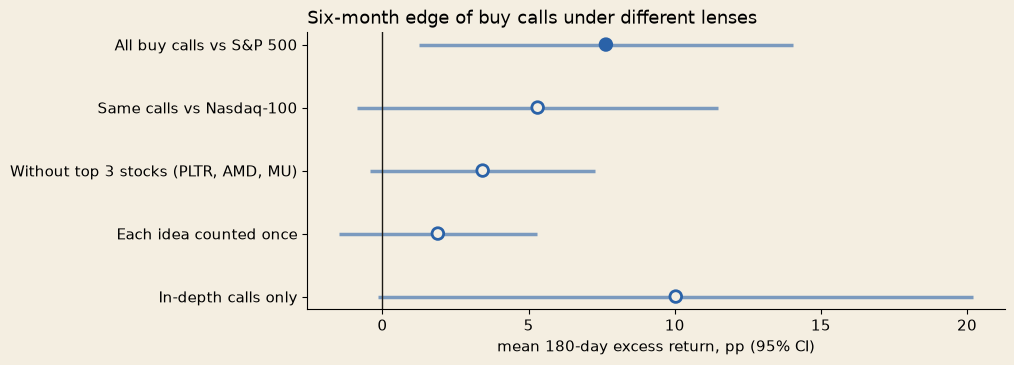

,n,mean,ci_low,ci_high,p
All buy calls vs S&P 500,4046.0,7.65,1.25,14.04,0.02
Same calls vs Nasdaq-100,4046.0,5.31,-0.86,11.48,0.09
"Without top 3 stocks (PLTR, AMD, MU)",3800.0,3.43,-0.41,7.27,0.08
Each idea counted once,1575.0,1.90,-1.49,5.28,0.26
In-depth calls only,1424.0,10.04,-0.14,20.21,0.05


In [8]:
H = 180
contrib = buy.groupby("ticker")[f"ex_{H}"].sum().nlargest(3).index
lenses = {
    "All buy calls vs S&P 500": clustered_mean(buy, f"ex_{H}"),
    "Same calls vs Nasdaq-100": clustered_mean(buy, f"exq_{H}"),
    f"Without top 3 stocks ({', '.join(contrib)})": clustered_mean(buy[~buy.ticker.isin(contrib)], f"ex_{H}"),
    "Each idea counted once": clustered_mean(buy[~buy.is_repeat_90d], f"ex_{H}"),
    "In-depth calls only": clustered_mean(buy[buy.in_depth], f"ex_{H}"),
}
L = pd.DataFrame(lenses).T
fig, ax = plt.subplots(figsize=(9, 3.6))
ypos = np.arange(len(L))[::-1]
ax.hlines(ypos, L.ci_low, L.ci_high, color=BLUE, lw=2.5, alpha=.6)
ax.scatter(L["mean"], ypos, s=70, color=[BLUE if lo > 0 else CREAM for lo in L.ci_low], edgecolor=BLUE, lw=2, zorder=3)
ax.axvline(0, color=INK, lw=1); ax.set_yticks(ypos); ax.set_yticklabels(L.index)
ax.set_xlabel(f"mean {H}-day excess return, pp (95% CI)")
ax.set_title("Six-month edge of buy calls under different lenses", loc="left")
plt.show(); L.round(2)

### Finding 3 - It made no difference whether a call was a recommendation or a warning

In [9]:
rows = []
for h in HORIZONS:
    b, s = clustered_mean(buy, f"ex_{h}"), clustered_mean(bear, f"ex_{h}")
    rows.append({"horizon": f"{h}d", "buy mean (pp)": b["mean"], "bearish mean (pp)": s["mean"],
                 "difference (pp)": b["mean"] - s["mean"], "n buy": int(b.n), "n bearish": int(s.n)})
pd.DataFrame(rows).set_index("horizon").round(2)

,buy mean (pp),bearish mean (pp),difference (pp),n buy,n bearish
horizon,,,,,
30d,0.28,0.50,-0.21,4046,1323
90d,2.24,1.53,0.71,4046,1323
180d,7.65,4.34,3.30,4046,1323
365d,11.61,13.08,-1.46,3126,990


The stocks creators warned about did roughly as well, relative to the index, as the stocks
they recommended. Remember that the bearish label is only right about 40% of the time, which
pulls any true difference towards zero. The case-study page adds a timing test (shifting all
calls to other dates) that does not depend on that label and reaches the same conclusion.

### Finding 4 - No channel was clearly better than the others

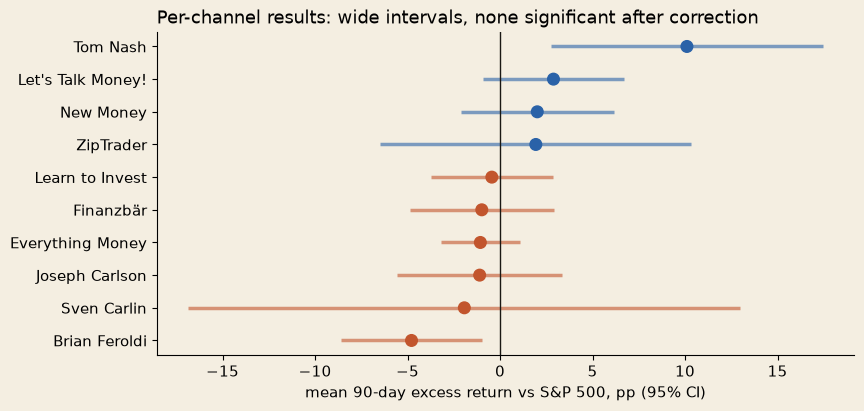

,n,mean,ci_low,ci_high,p,p (Holm),stocks,top stock,top stock share (%)
Tom Nash,471.0,10.101671,2.772644,17.430697,0.008948,0.089476,61,PLTR,21.443737
"Let's Talk Money! with Joseph Hogue, CFA",1666.0,2.886984,-0.901413,6.675381,0.128854,1.000000,390,SMCI,4.921969
New Money,98.0,2.012022,-2.134353,6.158396,0.324399,1.000000,44,AAPL,7.142857
ZipTrader,490.0,1.934023,-6.465885,10.333931,0.638358,1.000000,178,PLTR,7.755102
Learn to Invest,55.0,-0.443727,-3.739322,2.851868,0.776982,1.000000,33,MSFT,14.545455
Finanzbär,156.0,-0.986747,-4.889153,2.915658,0.606545,1.000000,88,HIMS,11.538462
Everything Money,724.0,-1.064421,-3.193846,1.065004,0.312513,1.000000,125,NKE,6.906077
Joseph Carlson,218.0,-1.102244,-5.558746,3.354259,0.614384,1.000000,36,GOOGL,11.46789
Sven Carlin,61.0,-1.930454,-16.844086,12.983177,0.708046,1.000000,26,BRK-B,22.95082
Brian Feroldi,75.0,-4.785448,-8.572917,-0.997978,0.016924,0.152319,43,AAPL,9.333333


In [10]:
rows = {}
for ch, g in buy.dropna(subset=["ex_90"]).groupby("channel"):
    if len(g) >= 50:
        s = clustered_mean(g, "ex_90"); top = g.ticker.value_counts()
        rows[ch] = {**s, "stocks": g.ticker.nunique(), "top stock": top.index[0], "top stock share (%)": top.iloc[0] / len(g) * 100}
C = pd.DataFrame(rows).T.sort_values("mean")
# Holm correction for testing several channels at once
p_sorted = C["p"].astype(float).sort_values(); m = len(p_sorted); adj, run = {}, 0
for k, (ch, p) in enumerate(p_sorted.items()):
    run = max(run, min(1, p * (m - k))); adj[ch] = run
C["p (Holm)"] = pd.Series(adj)
fig, ax = plt.subplots(figsize=(9, 4.2))
ypos = np.arange(len(C))
cols = [BLUE if v >= 0 else RUST for v in C["mean"]]
ax.hlines(ypos, C.ci_low.astype(float), C.ci_high.astype(float), color=cols, lw=2.5, alpha=.6)
ax.scatter(C["mean"].astype(float), ypos, s=70, color=cols, zorder=3)
ax.axvline(0, color=INK, lw=1); ax.set_yticks(ypos); ax.set_yticklabels([c.split(" with ")[0] for c in C.index])
ax.set_xlabel("mean 90-day excess return vs S&P 500, pp (95% CI)")
ax.set_title("Per-channel results: wide intervals, none significant after correction", loc="left")
plt.show()
C[["n", "mean", "ci_low", "ci_high", "p", "p (Holm)", "stocks", "top stock", "top stock share (%)"]].sort_values("mean", ascending=False)

## 5. Share

The full case study with interactive charts, the cleaning funnel, the audit and the method
notes lives on the project page; code and data journal are in the repository.

## 6. Act

1. **If you watch finance YouTube:** treat a recommendation as an idea to look into, and take
   your time. The days right after a video were no better a time to buy than any other.
2. **If you rank creators or analysts:** compare with the index, count each idea once, show the
   uncertainty, and leave out anyone with only a few dozen calls.
3. **If you extract data with a language model:** read a sample yourself before you trust it.

### Limitations
One market regime (2024-2026, tech-led); noisy machine labels; twelve hand-picked channels;
no trading costs; delisted companies are missing from this Yahoo-based reproduction.
Nothing here is investment advice.